In [5]:
# Hạ transformers về v4.x theo đúng yêu cầu của Microsoft Phi-4
!pip install -q "transformers==4.48.2" "accelerate==1.3.0" "peft==0.13.2" \
    backoff soundfile scipy "pillow>=11.0,<12.0" tqdm torchvision

Đang tải dataset MMHal-Bench...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 110 files:   0%|          | 0/110 [00:00<?, ?it/s]

Tải thành công! Tổng số câu hỏi: 96
Ảnh mẫu 0: (1107, 1500) - Câu hỏi: What color is the fire hydrant cap in the picture?


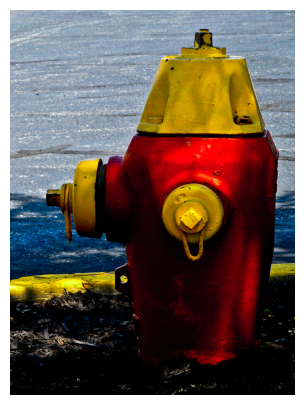

In [1]:
import os
import json
from PIL import Image
import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download

print("Đang tải dataset MMHal-Bench...")
snapshot_download(
    repo_id="Shengcao1006/MMHal-Bench",
    repo_type="dataset",
    local_dir="MMHal-Bench"
)

with open("MMHal-Bench/response_template.json", "r", encoding="utf-8") as f:
    benchmark_data = json.load(f)

print(f"Tải thành công! Tổng số câu hỏi: {len(benchmark_data)}")

# Kiểm tra ảnh mẫu
sample = benchmark_data[0]
img = Image.open(os.path.join("MMHal-Bench", "images", os.path.basename(sample["image_src"]))).convert("RGB")
print(f"Ảnh mẫu 0: {img.size} - Câu hỏi: {sample['question']}")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

In [2]:
# ===== CELL 3: Nạp model Phi-4 (FP16, offload mạnh hơn) =====
import torch, os
from transformers import AutoModelForCausalLM, AutoProcessor

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

model_id = "microsoft/Phi-4-multimodal-instruct"

print("Đang nạp processor...")
processor = AutoProcessor.from_pretrained(model_id, trust_remote_code=True)

print("Đang nạp model Phi-4 (FP16, offload ~5GB sang CPU)...")
print("⏳ Mất ~5 phút...")
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    trust_remote_code=True,
    device_map="auto",
    max_memory={0: "8GiB", "cpu": "10GiB"},
    offload_folder="offload",          # Nếu CPU RAM không đủ → offload tiếp ra disk
    low_cpu_mem_usage=True,
    _attn_implementation="eager",
)

vram_used = torch.cuda.memory_allocated()/1024**3
print(f"✅ Model sẵn sàng!")
print(f"   VRAM dùng: {vram_used:.1f} GB / 14.6 GB (còn trống: {14.6-vram_used:.1f} GB)")

Đang nạp processor...


/usr/local/lib/python3.13/dist-packages/transformers/models/auto/image_processing_auto.py:590: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Đang nạp model Phi-4 (FP16, offload ~5GB sang CPU)...
⏳ Mất ~5 phút...


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

✅ Model sẵn sàng!
   VRAM dùng: 8.0 GB / 14.6 GB (còn trống: 6.6 GB)


In [3]:
# ===== CELL 4: Hàm inference =====
from PIL import Image
import os

model.eval()

def ask_phi4(image, question_text):
    image = image.convert("RGB")

    # Resize ảnh nếu quá lớn để giảm VRAM cho activations
    max_size = 720
    if max(image.size) > max_size:
        image.thumbnail((max_size, max_size), Image.LANCZOS)

    prompt = f'<|user|><|image_1|>{question_text}<|end|><|assistant|>'

    # Xóa cache GPU trước mỗi lần inference
    torch.cuda.empty_cache()

    inputs = processor(text=prompt, images=image, return_tensors='pt')
    inputs = {
        k: v.to(model.device) if v is not None and hasattr(v, 'to') else v
        for k, v in inputs.items()
    }

    with torch.no_grad():
        generate_ids = model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
        )

    generate_ids = generate_ids[:, inputs['input_ids'].shape[1]:]
    response = processor.batch_decode(
        generate_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0].strip()

    # Giải phóng bộ nhớ
    del inputs, generate_ids
    torch.cuda.empty_cache()

    return response

# Test mẫu 0
sample_test = benchmark_data[0]
img_test = Image.open(os.path.join("MMHal-Bench", "images", os.path.basename(sample_test["image_src"])))
answer = ask_phi4(img_test, sample_test["question"])

print("Câu hỏi:", sample_test["question"])
print("Phi-4 trả lời:", answer)
print("Đáp án chuẩn:", sample_test["gt_answer"])

Câu hỏi: What color is the fire hydrant cap in the picture?
Phi-4 trả lời: The fire hydrant cap in the picture is yellow.
Đáp án chuẩn: The color of the fire hydrant cap in the image is yellow.


In [4]:
from tqdm import tqdm

print("Bắt đầu chạy benchmark MMHal-Bench (96 câu hỏi)...")

for i, item in enumerate(tqdm(benchmark_data, desc="Đang đánh giá")):
    img_path = os.path.join("MMHal-Bench", "images", os.path.basename(item["image_src"]))

    try:
        image = Image.open(img_path).convert("RGB")
        item["model_answer"] = ask_phi4(image, item["question"])
    except Exception as e:
        print(f"Lỗi tại mẫu {i}: {e}")
        item["model_answer"] = f"Error: {str(e)}"

output_file = "phi4_mmhal_responses.json"
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(benchmark_data, f, ensure_ascii=False, indent=2)

print(f"\nĐã hoàn thành! File kết quả: {output_file}")

Bắt đầu chạy benchmark MMHal-Bench (96 câu hỏi)...


Đang đánh giá: 100%|██████████| 96/96 [44:46<00:00, 27.99s/it]


Đã hoàn thành! File kết quả: phi4_mmhal_responses.json


In [5]:
from google.colab import files
files.download("phi4_mmhal_responses.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>